In [1]:
from matplotlib import pyplot as plt
import cv2
import numpy as np

In [2]:
rgb = cv2.imread('calib/3d/img_0001.jpg')

In [3]:
rgb.shape

(480, 752, 3)

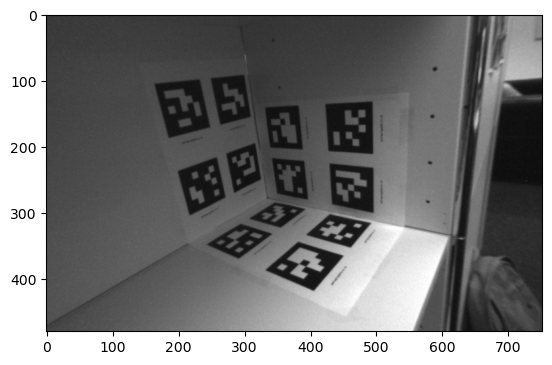

In [4]:
plt.imshow(rgb)

In [5]:
det_corners = np.loadtxt('calib/3d/detected_corners.txt')

In [6]:
det_corners

array([[186.5, 187.5, 264.5, ..., 280.5, 496.5, 300.5],
       [186.5, 186.5, 264.5, ..., 279.5, 496.5, 300.5],
       [187.5, 186.5, 265.5, ..., 279.5, 496.5, 300.5],
       ...,
       [220.5, 216.5, 293.5, ..., 306.5, 547.5, 319.5],
       [214.5, 226.5, 289.5, ..., 313.5, 542.5, 327.5],
       [208.5, 236.5, 283.5, ..., 322.5, 537.5, 336.5]])

In [7]:
X = det_corners[:,0::2]
Y = det_corners[:,1::2]

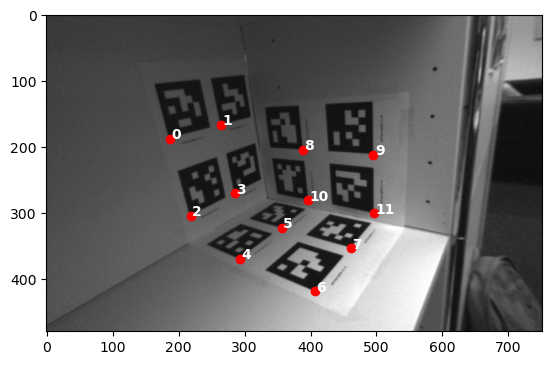

In [8]:
plt.imshow(rgb)
plt.plot(X[0,:], Y[0,:],'ro')
# Etiquetar cada punto con el número de su fila/índice
for i in range(len(X[0, :])):
    # (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
    plt.text(X[0, i] + 2, Y[0, i], str(i), color='white', fontsize=10, weight='bold')

plt.show()



In [9]:
real_corners = np.loadtxt('calib/3d/p_W_corners.txt',delimiter=',')

In [10]:
real_corners


array([[  0.  ,   8.  ,   0.  ],
       [ 10.4 ,   8.  ,   0.  ],
       [  0.  ,  21.5 ,   0.  ],
       [ 10.4 ,  21.5 ,   0.  ],
       [  0.  ,  26.6 , -10.95],
       [ 10.4 ,  26.6 , -10.95],
       [  0.  ,  26.6 , -24.45],
       [ 10.4 ,  26.6 , -24.45],
       [ 19.4 ,  14.6 , -10.95],
       [ 19.4 ,  14.6 , -24.45],
       [ 19.4 ,  25.  , -10.95],
       [ 19.4 ,  25.  , -24.45]])

In [11]:
Xw, Yw, Zw = real_corners[:,0], real_corners[:,1],real_corners[:,2]
Xw

array([ 0. , 10.4,  0. , 10.4,  0. , 10.4,  0. , 10.4, 19.4, 19.4, 19.4,
       19.4])

In [12]:
import plotly.express as px
import pandas as pd
import plotly.io as pio
pio.renderers.default = 'iframe'  # O prueba con 'notebook'

df = pd.DataFrame({'x': Xw,'y': Zw,'z': -Yw})

# Crear el gráfico de dispersión 3D interactivo
fig = px.scatter_3d(df, x='x', y='y', z='z', title='Gráfico 3D Interactivo')
# Mostrar el gráfico (se abrirá en tu navegador o notebook)
fig.show()

KeyboardInterrupt: 